In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
iris=pd.read_csv(r"C:\Users\KIIT\Downloads\iris\iris.data",header=None)
iris

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [37]:
iris.columns=['sl','sw','pl','pw','Class']
iris

,sl,sw,pl,pw,Class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [38]:
iris.Class.unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [39]:
iris.isnull().sum()

sl       0
sw       0
pl       0
pw       0
Class    0
dtype: int64

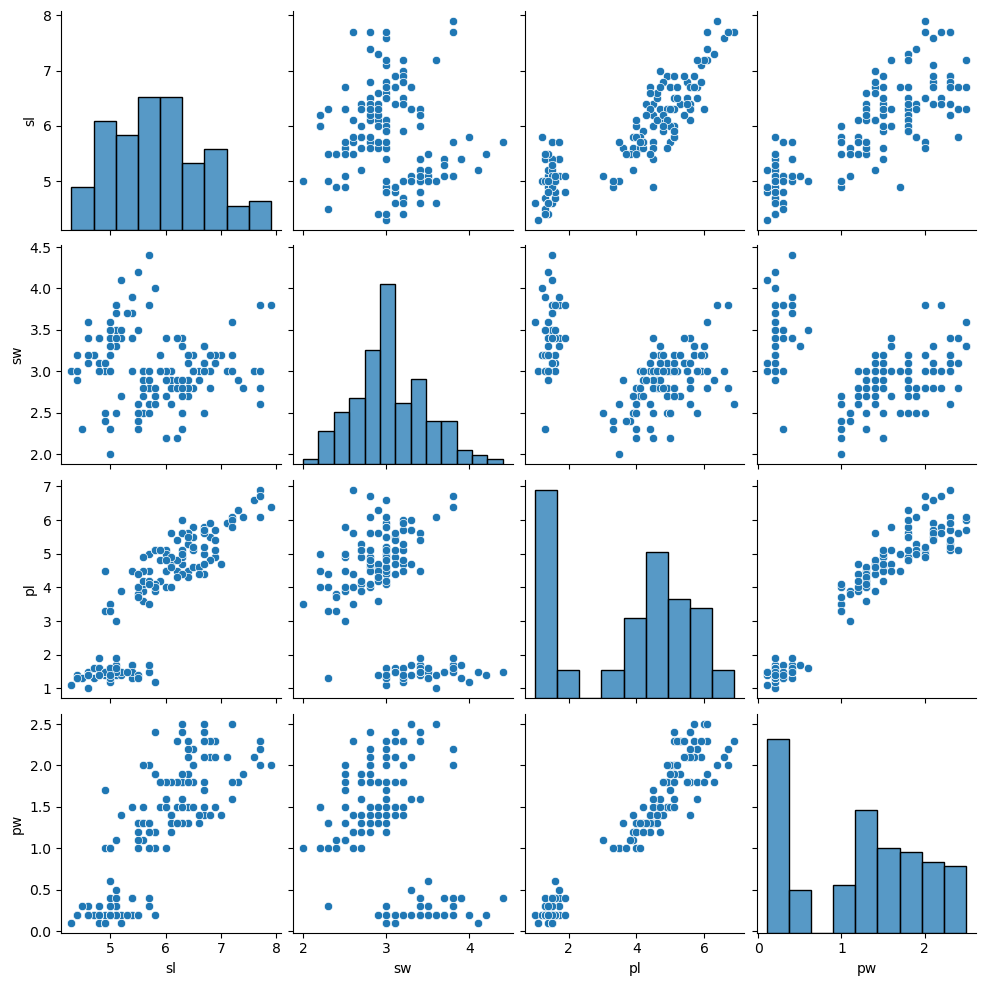

In [40]:
sns.pairplot(iris)
plt.show()

In [41]:
#drop the output column
iris=iris.drop('Class',axis=1)

iris

In [42]:
#K-means clustering
from sklearn.cluster import KMeans
km=KMeans(n_clusters=3)
km.fit(iris)

C:\Users\KIIT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3)

In [43]:
km_pred=km.predict(iris)
km_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0])

In [44]:
centroid=km.cluster_centers_
centroid

array([[5.9016129 , 2.7483871 , 4.39354839, 1.43387097],
       [5.006     , 3.418     , 1.464     , 0.244     ],
       [6.85      , 3.07368421, 5.74210526, 2.07105263]])

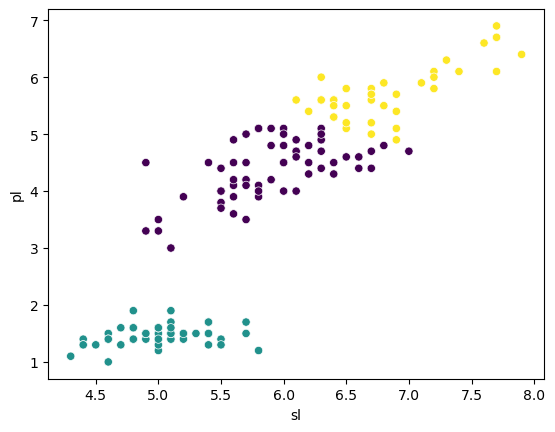

In [45]:
sns.scatterplot(x=iris.sl,y=iris.pl,c=km_pred)
plt.show()

[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.418      1.464      0.244     ]
 [6.85       3.07368421 5.74210526 2.07105263]]


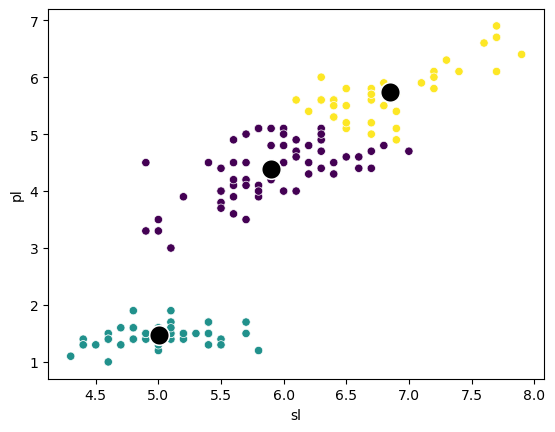

In [46]:
sns.scatterplot(x=iris.sl,y=iris.pl,c=km_pred)
print(centroid)
sns.scatterplot(x=centroid[::,0],y=centroid[::,2],s=200,color='k')
plt.show()

#sl sw pl pw
#           setosa
#           versicolor
#           virginica

## DBSCAN(Density Based Spatial Clustering With Noise)

In [47]:
main=pd.read_csv(r"C:\Users\KIIT\Downloads\maintenance_data.csv")
main

,lifetime,broken,pressureInd,moistureInd,temperatureInd,team,provider
0,56,0,92.178854,104.230204,96.517159,TeamA,Provider4
1,81,1,72.075938,103.065701,87.271062,TeamC,Provider4
2,60,0,96.272254,77.801376,112.196170,TeamA,Provider1
3,86,1,94.406461,108.493608,72.025374,TeamC,Provider2
4,34,0,97.752899,99.413492,103.756271,TeamB,Provider1
...,...,...,...,...,...,...,...
995,88,1,88.589759,112.167556,99.861456,TeamB,Provider4
996,88,1,116.727075,110.871332,95.075631,TeamA,Provider4
997,22,0,104.026778,88.212873,83.221220,TeamB,Provider1
998,78,0,104.911649,104.257296,83.421491,TeamA,Provider4


In [48]:
ip=main[['lifetime','pressureInd','moistureInd','temperatureInd']]
ip

,lifetime,pressureInd,moistureInd,temperatureInd
0,56,92.178854,104.230204,96.517159
1,81,72.075938,103.065701,87.271062
2,60,96.272254,77.801376,112.196170
3,86,94.406461,108.493608,72.025374
4,34,97.752899,99.413492,103.756271
...,...,...,...,...
995,88,88.589759,112.167556,99.861456
996,88,116.727075,110.871332,95.075631
997,22,104.026778,88.212873,83.221220
998,78,104.911649,104.257296,83.421491


In [49]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
ip=sc.fit_transform(ip)
ip

array([[ 0.03042386, -0.32176317,  0.4861391 , -0.20951597],
       [ 0.9752642 , -1.32922274,  0.36949902, -0.68069687],
       [ 0.18159831, -0.11662202, -2.16105066,  0.58948615],
       ...,
       [-1.254559  ,  0.27199669, -1.11820431, -0.88707673],
       [ 0.86188336,  0.31634205,  0.48885264, -0.87687093],
       [ 0.29497915,  0.91720728,  0.06229843, -2.70021891]])

In [50]:
from sklearn.cluster import DBSCAN
db=DBSCAN(eps=0.8,min_samples=5)
pred=db.fit_predict(ip)
pred

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
       -1, -1,  0, -1, -1, -1,  0,  0, -1,  0,  1, -1,  0,  0,  0,  0,  0,
        0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,
        0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0, -1,  0,  0,  0,  0, -1,  0,  0,  0,  0, -1, -1,  0,
        0, -1,  0, -1,  0

In [51]:
main['Prediction']=pred
main.head()

,lifetime,broken,pressureInd,moistureInd,temperatureInd,team,provider,Prediction
0,56,0,92.178854,104.230204,96.517159,TeamA,Provider4,0
1,81,1,72.075938,103.065701,87.271062,TeamC,Provider4,0
2,60,0,96.272254,77.801376,112.196170,TeamA,Provider1,0
3,86,1,94.406461,108.493608,72.025374,TeamC,Provider2,0
4,34,0,97.752899,99.413492,103.756271,TeamB,Provider1,0


In [52]:
main['Prediction'].value_counts()

Prediction
 0    871
-1    123
 1      6
Name: count, dtype: int64